<a href="https://colab.research.google.com/github/vassokouts/ml_auth/blob/main/Vasiliki_Koutsoupia_260_ML_Project_1_Part_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libraries

In [140]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

from sklearn.linear_model import Ridge



# Load Dataset

In [9]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


# Part 1: Logistic Regression
# Q1

* Pregnancies: πόσες εγκυμοσύνες έχει πραγματοποιήσει

* Glucose: Γλυκόζη

* BloodPressure: Αρτιακή πίεση

* SkinThickness: Πάχος δέρματος

* Insulin: Επίπεδα Ινσουλίνης στο αίμα

* BMI: Δείκτης μάζας σώματος

* DiabetesPedigreeFunction: Δείκτης που υπολογίζει την πιθανότητα εμφάνισης διαβήτη με βάση το οικογενειάκο ιστορίκο και τη συγγένια με ασθενείς

* Age: Ηλικία

* Outcome: έχει ή δεν έχει διαβήτη (ground truth τιμές)




In [14]:
df.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
mean,3.845,120.895,69.105,20.536,79.799,31.993,0.472,33.241,0.349
std,3.370,31.973,19.356,15.952,115.244,7.884,0.331,11.760,0.477
min,0.000,0.000,0.000,0.000,0.000,0.000,0.078,21.000,0.000
max,17.000,199.000,122.000,99.000,846.000,67.100,2.420,81.000,1.000


# Findings

To dataset αφορά 768 ασθενείς και καταγράφει αν νοσούν ή οχι απο διαβήτη (outcome). Η μεση ηλικία (mean age) είναι τα 33 χρόνια [21-81] και η μέση τιμή της γλυκόζης (glucose) είναι 120,89 [0-199] και της ινσουλίνης (insulin) 79,8 [0-846]. Περίπου το 35% του δείγματος είναι θετικό στον διαβήτη (mean outcome).

*Οι μηδενικές τιμές σε κάποιες από τις μεταβλητές προκαλούν ανησυχία ανάλογα με την εγκυρότητα του dtset.*



# Plot Variables

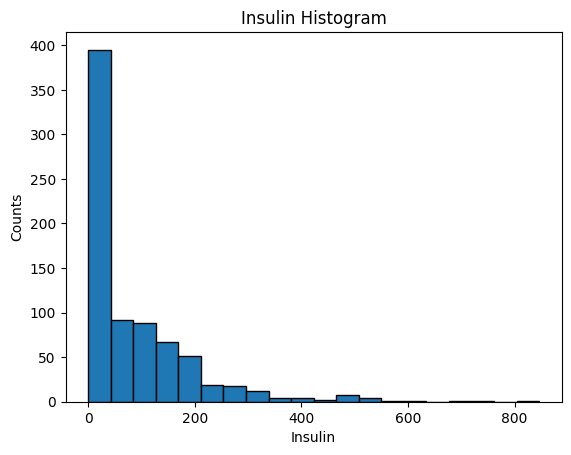

In [4]:
df['Insulin'].hist(bins=20, edgecolor='black')
plt.title('Insulin Histogram')
plt.xlabel('Insulin')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

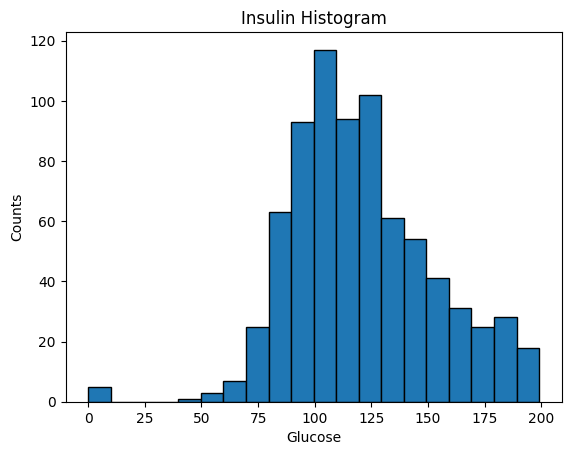

In [5]:
df['Glucose'].hist(bins=20, edgecolor='black')
plt.title('Insulin Histogram')
plt.xlabel('Glucose')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

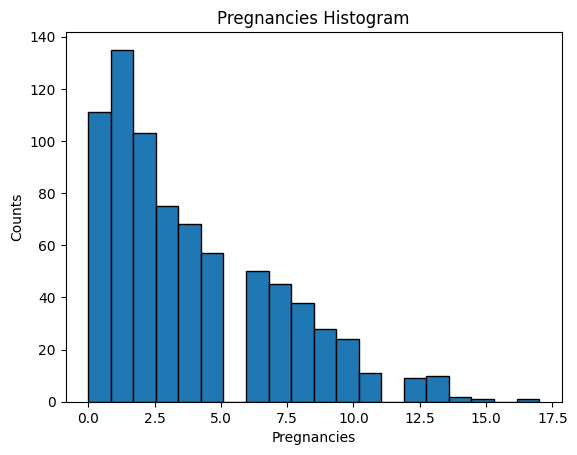

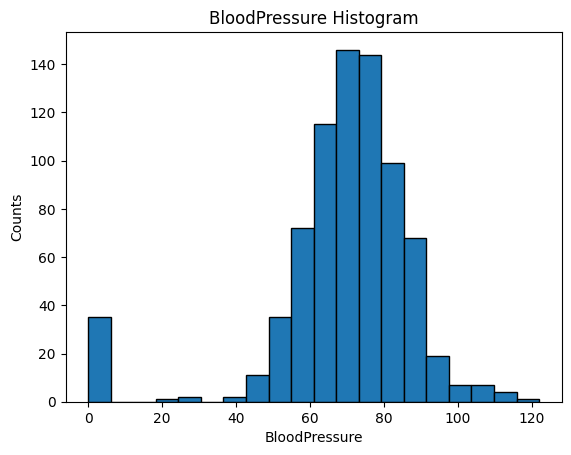

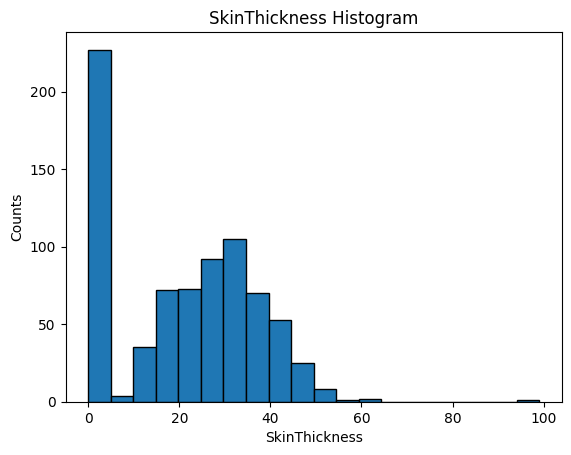

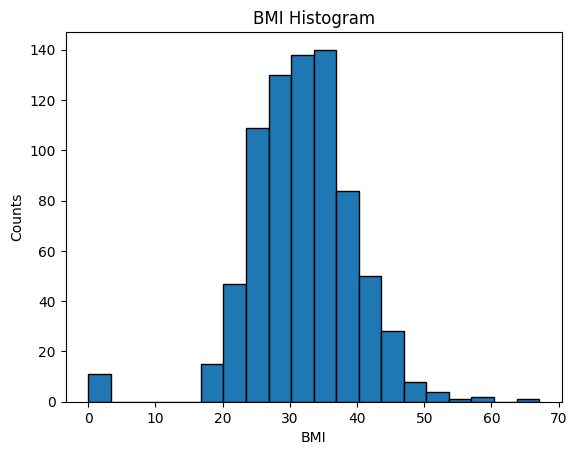

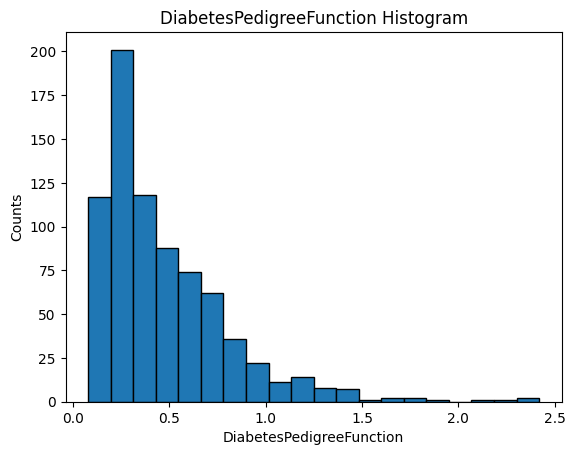

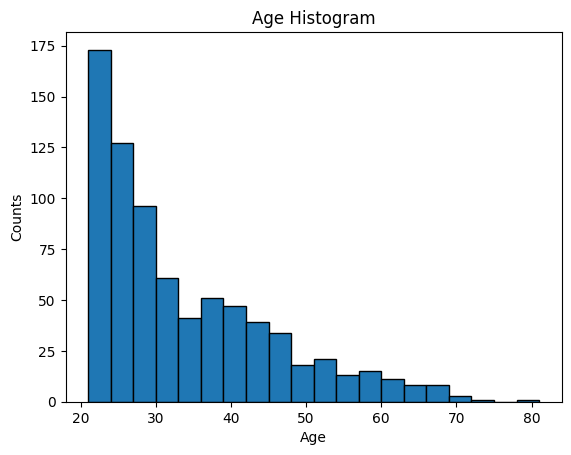

In [18]:
for column in df.columns:
    if column not in ['Outcome', 'Insulin', 'Glucose']:
        df[column].hist(bins=20, edgecolor='black')
        plt.title(column + ' Histogram')
        plt.xlabel(column)
        plt.ylabel('Counts')
        plt.grid(False)
        plt.show()

Outcome barplot

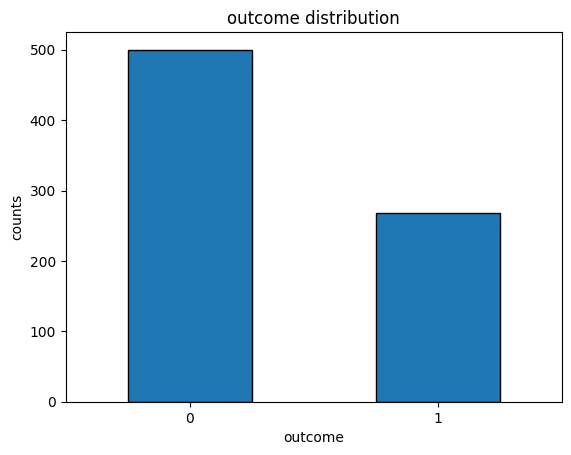

In [30]:
df['Outcome'].value_counts().sort_index().plot(kind='bar', edgecolor='black')
plt.title('outcome distribution')
plt.xlabel('outcome')
plt.ylabel('counts')
plt.grid(False)
plt.xticks(rotation=0)
plt.show()

# Q2
# Convert DataFrame to Numpy arrays

In [106]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

# Split Dataset to Train-Test

Train Samples: 70% of 768: 537 x 1

Test Samples: 30% of total samples: 231 x 8 (variables)

Seed: 0

Seed enables reproducibility

In [107]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 8), (537,), (231, 8), (231,))

# Q3
# Create a Logistic Regression Model

In [108]:
model = LogisticRegression(max_iter=5000, random_state=seed) #seed=0

# Train model on training set

In [109]:
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

# Evaluate Model on test set

In [110]:
# test set
y_pred = model.predict(x_test)
y_pred

# train set
y_pred_train = model.predict(x_train)
y_pred_train


array([1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,

In [111]:
## test set
test_accuracy = accuracy_score(y_test, y_pred)
test_accuracy_percentage = round(test_accuracy*100, 2)

print(f'The accuracy of the model in test set is: {test_accuracy_percentage}%')

## train set
train_accuracy = accuracy_score(y_train, y_pred_train)
train_accuracy_percentage = round(train_accuracy*100, 2)

print(f'the accuracy in train set is: {train_accuracy_percentage}%')

The accuracy of the model in test set is: 77.92%
the accuracy in train set is: 76.54%


Η ακρίβεια στο test set (77,92%) ειναι ελαφρώς υψηλότερη από ότι στο train set (76,54%). Κάτι τέτοιο δεν φαίνεται να αποτελεί πρόβλημα overfitting διότι η διαφορά είναι μικρή και οι τιμές είναι κοντά (το επιθυμητό). Επομένως θα λέγαμε ότι κάτι τέτοιο μπορεί να συμβαίνει λογώ της τυχαιότητας του διαχωρισμού των δεδομένων κατα train-test. Δεν έχουμε πολλές ενδείξεις για να το αξιολογήσουμε ως πρόβλημα.

# Feature Importance

Retrain the model using standard scaling. Then, investigate coefficients. Larger coefficient values $\rightarrow$ more important features

## Data Normalization

In [112]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train_scaler = scaler.transform(x_train)
x_test_scaler = scaler.transform(x_test)

## Model Training-Evaluation

In [113]:
model.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaler)
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 77.92


## Q4

Με βάση το ραβδόγραμμα παρατηρούμε οτι η γλυκοζη επηρεάζει περισσότερο τις προβλέψεις από οποιαδήποτε άλλη μεταβλητή, έχοντας τον μεγαλύτερο συντελεστή (λίγο μεγαλύτερός του 1). Συνεπώς φαίνεται αν είναι το σημαντικότερο χαρακτηριστικό για τα prediction του μοντέλου. Αυτό δείχνει ότι μεγαλυτερα επίπεδα γλυκόζης συνδέονται με μεγαλύτερη προβλεπόμενη πιθανότητα εμφάνισης διαβήτη, εφόσον το βάρος της γλυκόζης είναι θετικό.(and it is) Δείχνει δηλάδη θετική σχέση στο trained model. **κείμενο με έντονη γραφή**

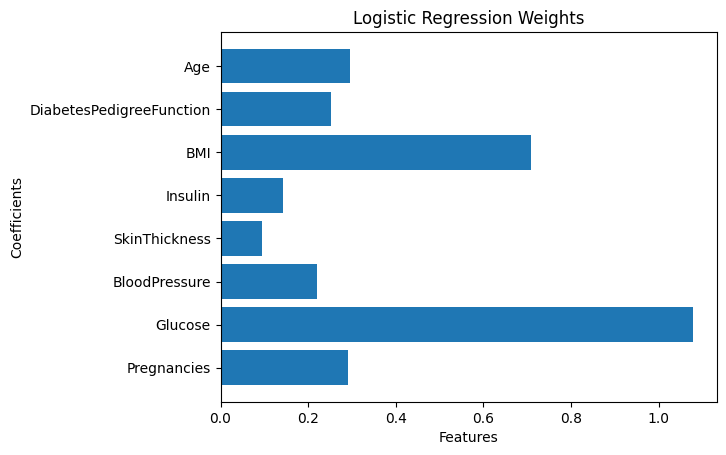

1.078


In [114]:
coeffs = model.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

# lets see if glucose's weight is positive or negative
print(coeffs[input_df.columns.get_loc('Glucose')].round(3))


## Q5

Φαίνεται ότι δουλεύει καλύτερα (έχει υψηλότερη ακρίβεια) για τις ηλικίες που είναι μεγαλύτερες των 50, μετά για τις 0-25 και έπειτα για τις 25-50. Η απόδοση του μοντέλου διαφοροποιείται ανάλογα με την ηλικιάλη ομάδα.


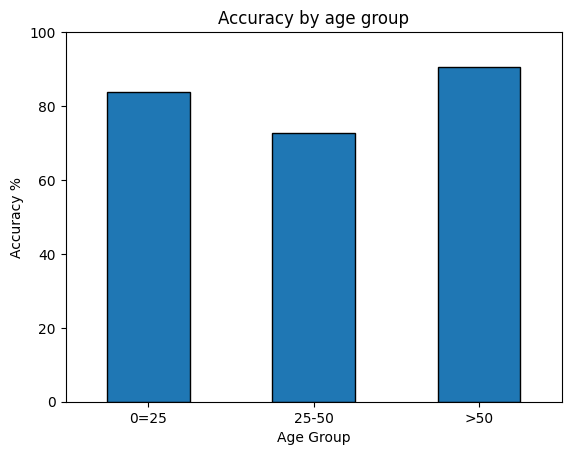

In [118]:
y_pred = model.predict(x_test_scaled)
ages = x_test[:, df.columns.get_loc('Age')]

age_grps = pd.cut(ages, bins=[0,24,50,float('inf')], labels=['0=25','25-50','>50'])
result = pd.DataFrame({'Age Group': age_grps, 'ages': y_test == y_pred})

acc_by_age = result.groupby('Age Group', observed=True)['ages'].mean() * 100

acc_by_age.plot(kind='bar',edgecolor='black')
plt.xlabel('Age Group')
plt.ylabel('Accuracy %')
plt.title('Accuracy by age group')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.grid(False)
plt.show()


##**κείμενο με έντονη γραφή** Q6
Για την συγκεκριμένη εφαρμογή χειρότερο θα ήταν το σφάλμα που αφορά τις false negative προβλέψεις, όταν δηλάδή προβλέπει ότι ένας ασθενής δεν έχει διαβήτη ενώ έχει. Αντιθέτα αν έχουμε πολλά false positives, με συγκεκριμένα ιατρικά βήματα ο ασθενής θα διαπιστώσει το λαθος χωρίς μεγάλο κόστος αναφορικά με την υγεία του. Αν όμως η διάγνωση είναι ψευδής και τελικά έχει, κάτι τέτοιο μπορεί να τον επαναπαύσει και να θέσει σε κίνδυνο την υγεία του.



# Part 2: Linear Regression
# Q1


In [121]:
features = ['BloodPressure','Pregnancies', 'BMI', 'Age']

x2 = df[features].to_numpy()
y2 = df['Glucose'].to_numpy()

x2.shape, y2.shape


# train-test split
x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y2, test_size=0.3, random_state=0)
x2_train.shape, y2_train.shape, x2_test.shape, y_test.shape

((537, 4), (537,), (231, 4), (231,))

## Q2


In [133]:
model2 = LinearRegression()
model2.fit(x2_train, y2_train)

y2_pred = model2.predict(x2_test)
y2_pred

mse= mean_squared_error(y2_test, y2_pred)
mae = mean_absolute_error(y2_test, y2_pred)

print(f'MSE: {mse}')
print(f'MAE: {mae}')



MSE: 929.8883492746901
MAE: 23.599990462075155


Μεταξύ των δύο μετρικών θα έλεγα ότι η καταλληλότερη είναι η MSE διότι θέλουμε να περιορίσουμε τα μεγάλα σφάλματα πρόβλεψης. Εφόσον θεωρούμε ότι για τιμή γλυκόζης πάνω απο 170 χορηγούνται εξετάσεις, εμείς επιλέγουμε την MSE που τιμώρει τα μεγάλα σφάλματα, και μια μεγάλη αποκλίση μπορεί να οδηγήσει εναν ασθενη σε περισσοτερες εξετασεις με βαση το οριο των 170.

# Q3

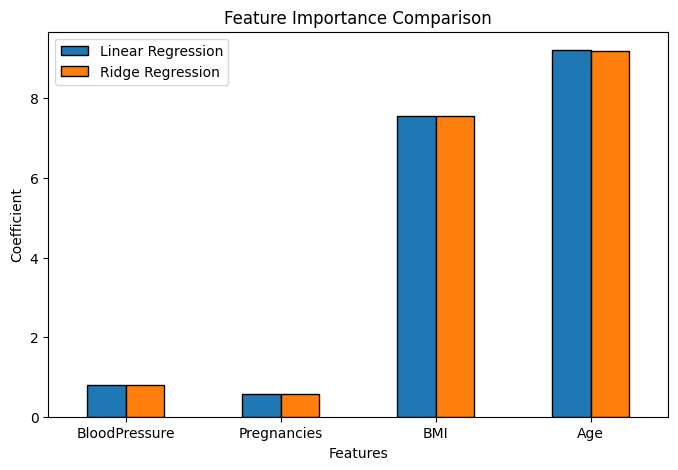

In [154]:

# lets scale
scaler_2 = StandardScaler()
x2_train_scaled = scaler_2.fit_transform(x2_train)
x2_test_scaled = scaler_2.transform(x2_test)

# linear regression with scaled features
model2_scaled = LinearRegression()
model2_scaled.fit(x2_train_scaled, y2_train)

# regularization
ridge_2 = Ridge(alpha=1.0)
ridge_2.fit(x2_train_scaled, y2_train)

linear_coeffs = np.abs(model2_scaled.coef_)
ridge_coeffs = np.abs(ridge_2.coef_)

compare = pd.DataFrame({
    'Linear Regression': linear_coeffs,
    'Ridge Regression': ridge_coeffs
}, index=features)

# one plot
compare.plot(kind='bar', figsize=(8, 5), edgecolor='black')
plt.title('Feature Importance Comparison')
plt.xlabel('Features')
plt.ylabel('Coefficient')
plt.xticks(rotation=0)
plt.grid(False)
plt.show()


Από την σύγκριση των συντελεστών προκύπτει ότι η ηλικία (age) ειναι η πιο σημαντική μεταβλητή για την πρόβλεψη της γλυκόζης και ακολουθεί το BMI. Εφαρμόζουμε data scaler ώστε οι μεταβλητές να βρίσκονται στην ίδια κλίμακα και να μπορούμε να συγκρίνουμε τους συντελεστές τους. Και έπειτα Ridge (L2) ομαλοποίηση. Παρατηρούμε οτι οι συντελεστές είναι σχεδόν οι ίδιοι. Η ομαλοποίηση εδώ δεν επηρεάζει σημαντικά τους συντελεστές με την ηλικία να παραμένει το πιο σημαντικό χαρακτηριστικό.